<a href="https://colab.research.google.com/github/dGabo-jr/CURSOS-DE-PYTHON/blob/main/Control_de_un_veh%C3%ADculo_para_quitar_obtaculos_con_red_de_2_entradas%2C_una_capa_oculta_y_2_salidas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Control de un vehículo para quitar obtaculos con red de 2 entradas, una capa oculta y 2 salidas, una función sigmoide

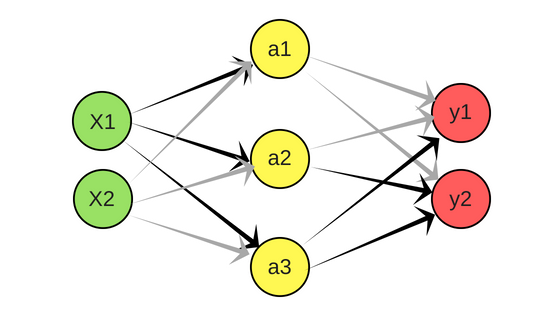

In [2]:
import numpy as np

def sigmoid(x):
    return 1.0/(1.0 + np.exp(-x))

def sigmoid_derivada(x):
    return sigmoid(x)*(1.0-sigmoid(x))

def tanh(x):
    return np.tanh(x)

def tanh_derivada(x):
    return 1.0 - x**2


class NeuralNetwork:

    def __init__(self, layers, activation='tanh'):
        if activation == 'sigmoid':
            self.activation = sigmoid
            self.activation_prime = sigmoid_derivada
        elif activation == 'tanh':
            self.activation = tanh
            self.activation_prime = tanh_derivada

        # inicializo los pesos
        self.weights = []
        self.deltas = []
        # capas = [2,3,2]
        # rando de pesos varia entre (-1,1)
        # asigno valores aleatorios a capa de entrada y capa oculta
        for i in range(1, len(layers) - 1):
            r = 2*np.random.random((layers[i-1] + 1, layers[i] + 1)) -1
            self.weights.append(r)
        # asigno aleatorios a capa de salida
        r = 2*np.random.random( (layers[i] + 1, layers[i+1])) - 1
        self.weights.append(r)

    def fit(self, X, y, learning_rate=0.2, epochs=100000):
        # Agrego columna de unos a las entradas X
        # Con esto agregamos la unidad de Bias a la capa de entrada
        ones = np.atleast_2d(np.ones(X.shape[0]))
        X = np.concatenate((ones.T, X), axis=1)

        for k in range(epochs):
            i = np.random.randint(X.shape[0])
            a = [X[i]]

            for l in range(len(self.weights)):
                    dot_value = np.dot(a[l], self.weights[l])
                    activation = self.activation(dot_value)
                    a.append(activation)
            # Calculo la diferencia en la capa de salida y el valor obtenido
            error = y[i] - a[-1]
            deltas = [error * self.activation_prime(a[-1])]

            # Empezamos en el segundo layer hasta el ultimo
            # (Una capa anterior a la de salida)
            for l in range(len(a) - 2, 0, -1):
                deltas.append(deltas[-1].dot(self.weights[l].T)*self.activation_prime(a[l]))
            self.deltas.append(deltas)

            # invertir
            # [level3(output)->level2(hidden)]  => [level2(hidden)->level3(output)]
            deltas.reverse()

            # backpropagation
            # 1. Multiplcar los delta de salida con las activaciones de entrada
            #    para obtener el gradiente del peso.
            # 2. actualizo el peso restandole un porcentaje del gradiente
            for i in range(len(self.weights)):
                layer = np.atleast_2d(a[i])
                delta = np.atleast_2d(deltas[i])
                self.weights[i] += learning_rate * layer.T.dot(delta)

            if k % 10000 == 0: print('epochs:', k)

    def predict(self, x):
        ones = np.atleast_2d(np.ones(x.shape[0]))
        a = np.concatenate((np.ones(1).T, np.array(x)), axis=0)
        for l in range(0, len(self.weights)):
            a = self.activation(np.dot(a, self.weights[l]))
        return a

    def print_weights(self):
        print("LISTADO PESOS DE CONEXIONES")
        for i in range(len(self.weights)):
            print(self.weights[i])

    def get_deltas(self):
        return self.deltas

In [3]:
# funcion Coche Evita obstáculos
nn = NeuralNetwork([2,3,2],activation ='tanh')
X = np.array([[0, 0],   # sin obstaculos
              [0, 1],   # sin obstaculos
              [0, -1],  # sin obstaculos
              [0.5, 1], # obstaculo detectado a derecha
              [0.5,-1], # obstaculo a izq
              [1,1],    # demasiado cerca a derecha
              [1,-1]])  # demasiado cerca a izq

y = np.array([[0,1],    # avanzar
              [0,1],    # avanzar
              [0,1],    # avanzar
              [-1,1],   # giro izquierda
              [1,1],    # giro derecha
              [0,-1],   # retroceder
              [0,-1]])  # retroceder
nn.fit(X, y, learning_rate=0.03,epochs=15001)

index=0
for e in X:
    print("X:",e,"y:",y[index],"Network:",nn.predict(e))
    index=index+1

epochs: 0
epochs: 10000
X: [0. 0.] y: [0 1] Network: [0.00280063 0.99998941]
X: [0. 1.] y: [0 1] Network: [-0.00399536  0.99998189]
X: [ 0. -1.] y: [0 1] Network: [-0.00523809  0.99995378]
X: [0.5 1. ] y: [-1  1] Network: [-0.94851739  0.95667788]
X: [ 0.5 -1. ] y: [1 1] Network: [0.95409394 0.94714579]
X: [1. 1.] y: [ 0 -1] Network: [-0.00207122 -0.97570904]
X: [ 1. -1.] y: [ 0 -1] Network: [ 0.00165    -0.96156866]


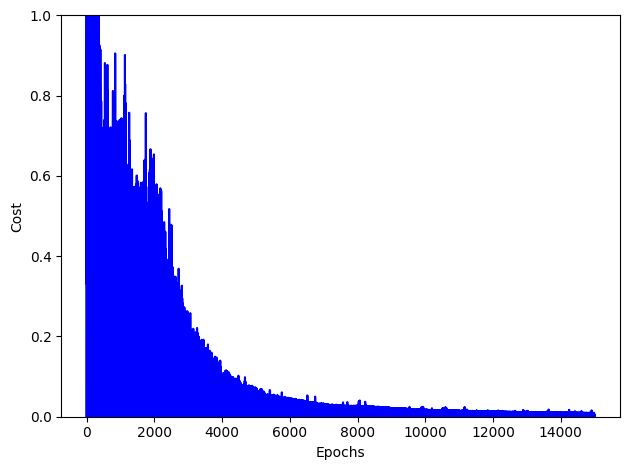

In [4]:
import matplotlib.pyplot as plt

deltas = nn.get_deltas()
valores=[]
index=0
for arreglo in deltas:
    valores.append(arreglo[1][0] + arreglo[1][1])
    index=index+1

plt.plot(range(len(valores)), valores, color='b')
plt.ylim([0, 1])
plt.ylabel('Cost')
plt.xlabel('Epochs')
plt.tight_layout()
plt.show()

In [5]:
# Red Coche para Evitar obstáculos
nn = NeuralNetwork([2,3,4],activation ='tanh')
X = np.array([[-1, 0],   # sin obstaculos
              [-1, 1],   # sin obstaculos
              [-1, -1],  # sin obstaculos
              [0, -1],   # obstaculo detectado a derecha
              [0,1],     # obstaculo a izq
              [0,0],     # obstaculo centro
              [1,1],     # demasiado cerca a derecha
              [1,-1],    # demasiado cerca a izq
              [1,0]      # demasiado cerca centro
             ])
# las salidas 'y' se corresponden con encender (o no) los motores
y = np.array([[1,0,0,1], # avanzar
              [1,0,0,1], # avanzar
              [1,0,0,1], # avanzar
              [0,1,0,1], # giro derecha
              [1,0,1,0], # giro izquierda (cambie izq y derecha)
              [1,0,0,1], # avanzar
              [0,1,1,0], # retroceder
              [0,1,1,0], # retroceder
              [0,1,1,0]  # retroceder
             ])
nn.fit(X, y, learning_rate=0.03,epochs=40001)

def valNN(x):
    return (int)(abs(round(x)))

index=0
for e in X:
    prediccion = nn.predict(e)
    print("X:",e,"esperado:",y[index],"obtenido:", valNN(prediccion[0]),valNN(prediccion[1]),valNN(prediccion[2]),valNN(prediccion[3]))
    index=index+1

epochs: 0
epochs: 10000
epochs: 20000
epochs: 30000
epochs: 40000
X: [-1  0] esperado: [1 0 0 1] obtenido: 1 0 0 1
X: [-1  1] esperado: [1 0 0 1] obtenido: 1 0 0 1
X: [-1 -1] esperado: [1 0 0 1] obtenido: 1 0 0 1
X: [ 0 -1] esperado: [0 1 0 1] obtenido: 0 1 0 1
X: [0 1] esperado: [1 0 1 0] obtenido: 1 0 1 0
X: [0 0] esperado: [1 0 0 1] obtenido: 1 0 0 1
X: [1 1] esperado: [0 1 1 0] obtenido: 0 1 1 0
X: [ 1 -1] esperado: [0 1 1 0] obtenido: 0 1 1 0
X: [1 0] esperado: [0 1 1 0] obtenido: 0 1 1 0


Crearemos una red neuronal simple, con 3 capas, neuronas con valores de entrada -1 a 1 y de salida 0 a 1 indicando encender o no los motores de un coche Arduino

In [6]:
import numpy as np

# Creamos la clase
class NeuralNetwork:

    def __init__(self, layers, activation='tanh'):
        if activation == 'sigmoid':
            self.activation = sigmoid
            self.activation_prime = sigmoid_derivada
        elif activation == 'tanh':
            self.activation = tanh
            self.activation_prime = tanh_derivada

        # inicializo los pesos
        self.weights = []
        self.deltas = []
        # capas = [2,3,4]
        # rando de pesos varia entre (-1,1)
        # asigno valores aleatorios a capa de entrada y capa oculta
        for i in range(1, len(layers) - 1):
            r = 2*np.random.random((layers[i-1] + 1, layers[i] + 1)) -1
            self.weights.append(r)
        # asigno aleatorios a capa de salida
        r = 2*np.random.random( (layers[i] + 1, layers[i+1])) - 1
        self.weights.append(r)

    def fit(self, X, y, learning_rate=0.2, epochs=100000):
        # Agrego columna de unos a las entradas X
        # Con esto agregamos la unidad de Bias a la capa de entrada
        ones = np.atleast_2d(np.ones(X.shape[0]))
        X = np.concatenate((ones.T, X), axis=1)

        for k in range(epochs):
            i = np.random.randint(X.shape[0])
            a = [X[i]]

            for l in range(len(self.weights)):
                    dot_value = np.dot(a[l], self.weights[l])
                    activation = self.activation(dot_value)
                    a.append(activation)
            # Calculo la diferencia en la capa de salida y el valor obtenido
            error = y[i] - a[-1]
            deltas = [error * self.activation_prime(a[-1])]

            # Empezamos en el segundo layer hasta el ultimo
            # (Una capa anterior a la de salida)
            for l in range(len(a) - 2, 0, -1):
                deltas.append(deltas[-1].dot(self.weights[l].T)*self.activation_prime(a[l]))
            self.deltas.append(deltas)

            # invertir
            # [level3(output)->level2(hidden)]  => [level2(hidden)->level3(output)]
            deltas.reverse()

            # backpropagation
            # 1. Multiplcar los delta de salida con las activaciones de entrada
            #    para obtener el gradiente del peso.
            # 2. actualizo el peso restandole un porcentaje del gradiente
            for i in range(len(self.weights)):
                layer = np.atleast_2d(a[i])
                delta = np.atleast_2d(deltas[i])
                self.weights[i] += learning_rate * layer.T.dot(delta)

            if k % 10000 == 0: print('epochs:', k)

    def predict(self, x):
        ones = np.atleast_2d(np.ones(x.shape[0]))
        a = np.concatenate((np.ones(1).T, np.array(x)), axis=0)
        for l in range(0, len(self.weights)):
            a = self.activation(np.dot(a, self.weights[l]))
        return a

    def print_weights(self):
        print("LISTADO PESOS DE CONEXIONES")
        for i in range(len(self.weights)):
            print(self.weights[i])

    def get_weights(self):
        return self.weights

    def get_deltas(self):
        return self.deltas

# Al crear la red, podremos elegir entre usar la funcion sigmoid o tanh
def sigmoid(x):
    return 1.0/(1.0 + np.exp(-x))

def sigmoid_derivada(x):
    return sigmoid(x)*(1.0-sigmoid(x))

def tanh(x):
    return np.tanh(x)

def tanh_derivada(x):
    return 1.0 - x**2

Comportamiento del Coche Robot
Crearemos una red neuronal que nos dará los pesos para las conexiones que utilizaremos en un coche robot Arduino

In [7]:
# Red Coche para Evitar obstáculos
nn = NeuralNetwork([2,3,4],activation ='tanh')
X = np.array([[-1, 0],   # sin obstaculos
              [-1, 1],   # sin obstaculos
              [-1, -1],  # sin obstaculos
              [0, -1],   # obstaculo detectado a derecha
              [0,1],     # obstaculo a izq
              [0,0],     # obstaculo centro
              [1,1],     # demasiado cerca a derecha
              [1,-1],    # demasiado cerca a izq
              [1,0]      # demasiado cerca centro
             ])
# las salidas 'y' se corresponden con encender (o no) los motores
y = np.array([[1,0,0,1], # avanzar
              [1,0,0,1], # avanzar
              [1,0,0,1], # avanzar
              [0,1,0,1], # giro derecha
              [1,0,1,0], # giro izquierda (cambie izq y derecha)
              [1,0,0,1], # avanzar
              [0,1,1,0], # retroceder
              [0,1,1,0], # retroceder
              [0,1,1,0]  # retroceder
             ])
nn.fit(X, y, learning_rate=0.03,epochs=40001)

def valNN(x):
    return (int)(abs(round(x)))

index=0
for e in X:
    prediccion = nn.predict(e)
    print("X:",e,"esperado:",y[index],"obtenido:", valNN(prediccion[0]),valNN(prediccion[1]),valNN(prediccion[2]),valNN(prediccion[3]))
    #print("X:",e,"y:",y[index],"Network:",prediccion)
    index=index+1

epochs: 0
epochs: 10000
epochs: 20000
epochs: 30000
epochs: 40000
X: [-1  0] esperado: [1 0 0 1] obtenido: 1 0 0 1
X: [-1  1] esperado: [1 0 0 1] obtenido: 1 0 0 1
X: [-1 -1] esperado: [1 0 0 1] obtenido: 1 0 0 1
X: [ 0 -1] esperado: [0 1 0 1] obtenido: 0 1 0 1
X: [0 1] esperado: [1 0 1 0] obtenido: 1 0 1 0
X: [0 0] esperado: [1 0 0 1] obtenido: 1 0 0 1
X: [1 1] esperado: [0 1 1 0] obtenido: 0 1 1 0
X: [ 1 -1] esperado: [0 1 1 0] obtenido: 0 1 1 0
X: [1 0] esperado: [0 1 1 0] obtenido: 0 1 1 0


Graficamos la función coste
Vemos como el gradiente desciende y disminuye el error a medida que pasan las iteraciones de aprendizaje

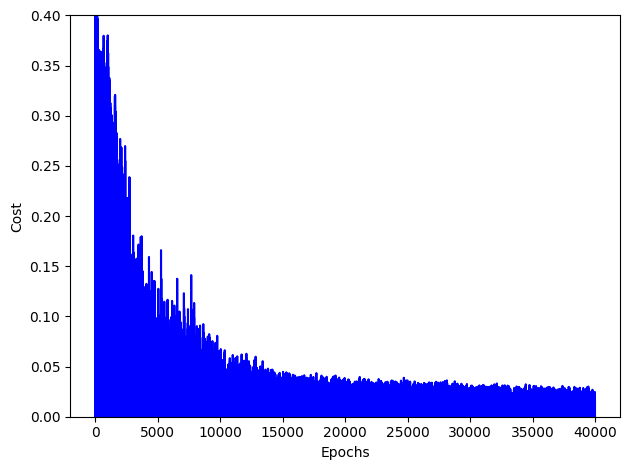

In [8]:
import matplotlib.pyplot as plt

deltas = nn.get_deltas()
valores=[]
index=0
for arreglo in deltas:
    valores.append(arreglo[1][0] + arreglo[1][1])
    index=index+1

plt.plot(range(len(valores)), valores, color='b')
plt.ylim([0, 0.4])
plt.ylabel('Cost')
plt.xlabel('Epochs')
plt.tight_layout()
plt.show()

##Generamos el código para Arduino

In [9]:
def to_str(name, W):
    s = str(W.tolist()).replace('[', '{').replace(']', '}')
    return 'float '+name+'['+str(W.shape[0])+']['+str(W.shape[1])+'] = ' + s + ';'

In [10]:
# Obtenermos los pesos entrenados para poder usarlos en el codigo de arduino
pesos = nn.get_weights();

print('// Reemplazar estas lineas en tu codigo arduino:')
print('// float HiddenWeights ...')
print('// float OutputWeights ...')
print('// Con lo pesos entrenados.')
print('\n')
print(to_str('HiddenWeights', pesos[0]))
print(to_str('OutputWeights', pesos[1]))

// Reemplazar estas lineas en tu codigo arduino:
// float HiddenWeights ...
// float OutputWeights ...
// Con lo pesos entrenados.


float HiddenWeights[3][4] = {{-1.0594803340960441, 1.0953280485887158, 1.1134305164257243, -0.8336042025729439}, {0.5173555524734773, -3.7691946149674522, -3.844906206949147, 0.6737299014624567}, {0.296310148654102, 1.6146794580212132, -1.6826450638492096, -0.24034446030331322}};
float OutputWeights[4][4] = {{-1.5932623232311327, -1.0109402041564548, -1.0994966723887216, -0.5683721584881487}, {1.6717469747091869, -1.809358779595448, -0.30263576873829884, -0.9501776285604535}, {-0.8031592001623753, -0.26373223068499513, -1.7300568138923456, 1.5160939593092972}, {-0.377353006558786, -1.2767472553513486, -1.1418519598577865, -1.7200649604700424}};


##Este es el código de arduino


#este código copialo y pégalo en tu ARDUINO IDE


In [12]:
#include <Servo.h>  //servo library
Servo myservo;      // create servo object to control servo

int Echo = A4;
int Trig = A5;
#define ENA 5
#define ENB 6
#define IN1 7
#define IN2 8
#define IN3 9
#define IN4 11

/******************************************************************
   Network Configuration
 ******************************************************************/
const int InputNodes = 3; // incluye neurona de BIAS
const int HiddenNodes = 4; //incluye neurona de BIAS
const int OutputNodes = 4;
int i, j;
double Accum;
double Hidden[HiddenNodes];
double Output[OutputNodes];
float HiddenWeights[3][4] = {{1.8991509504079183, -0.4769472541445052, -0.6483690220539764, -0.38609165249078925}, {-0.2818610915467527, 4.040695699457223, 3.2291858058243843, -2.894301104732614}, {0.3340650864625773, -1.4016114422346901, 1.3580053902963762, -0.981415976256285}};
float OutputWeights[4][4] = {{1.136072297461121, 1.54602394937381, 1.6194612259569254, 1.8819066696635067}, {-1.546966506764457, 1.3951930739494225, 0.19393826092602756, 0.30992504138547006}, {-0.7755982417649826, 0.9390808625728915, 2.0862510744685485, -1.1229484266101883}, {-1.2357090352280826, 0.8583930286034466, 0.724702079881947, 0.9762852709700459}};
/******************************************************************
   End Network Configuration
 ******************************************************************/

void stop() {
  digitalWrite(ENA, LOW); //Desactivamos los motores
  digitalWrite(ENB, LOW); //Desactivamos los motores
  Serial.println("Stop!");
}

//Medir distancia en Centimetros
int Distance_test() {
  digitalWrite(Trig, LOW);
  delayMicroseconds(2);
  digitalWrite(Trig, HIGH);
  delayMicroseconds(20);
  digitalWrite(Trig, LOW);
  float Fdistance = pulseIn(Echo, HIGH);
  Fdistance= Fdistance / 58;
  return (int)Fdistance;
}

void setup() {
  myservo.attach(3);  // attach servo on pin 3 to servo object
  Serial.begin(9600);
  pinMode(Echo, INPUT);
  pinMode(Trig, OUTPUT);
  pinMode(IN1, OUTPUT);
  pinMode(IN2, OUTPUT);
  pinMode(IN3, OUTPUT);
  pinMode(IN4, OUTPUT);
  pinMode(ENA, OUTPUT);
  pinMode(ENB, OUTPUT);
  stop();
  myservo.write(90);  //posicion inicial en el centro
  delay(500);
}

unsigned long previousMillis = 0;   // para medir ciclos de tiempo
const long interval = 25;           // intervalos cada x milisegundos
int grados_servo = 90;                // posicion del servo que mueve el sensor ultrasonico
bool clockwise = true;              // sentido de giro del servo
const long ANGULO_MIN = 30;
const long ANGULO_MAX = 150;
double ditanciaMaxima = 50.0;       // distancia de lejania desde la que empieza a actuar la NN
int incrementos = 9;                // incrementos por ciclo de posicion del servo
int accionEnCurso = 1;              // cantidad de ciclos ejecutando una accion
int multiplicador = 1000/interval;  // multiplica la cant de ciclos para dar tiempo a que el coche pueda girar
const int SPEED = 100;              // velocidad del coche de las 4 ruedas a la vez.

void loop() {
  unsigned long currentMillis = millis();

  if (currentMillis - previousMillis >= interval) {
    previousMillis = currentMillis;

  /******************************************************************
    MANEJAR GIRO de SERVO
  ******************************************************************/
    if(grados_servo<=ANGULO_MIN || grados_servo>=ANGULO_MAX){
      clockwise=!clockwise; // cambio de sentido
      grados_servo = constrain(grados_servo, ANGULO_MIN, ANGULO_MAX);
    }
    if(clockwise)
      grados_servo=grados_servo+incrementos;
    else
      grados_servo=grados_servo-incrementos;

    if(accionEnCurso>0){
      accionEnCurso=accionEnCurso-1;
    }else{
  /******************************************************************
    LLAMAMOS a la FUNCION DE CONDUCCION
  ******************************************************************/
       conducir();
    }
    myservo.write(grados_servo);
  }

}

//USA LA RED NEURONAL YA ENTRENADA
void conducir()
{
    double TestInput[] = {0, 0,0};
    double entrada1=0,entrada2=0;

  /******************************************************************
    OBTENER DISTANCIA DEL SENSOR
  ******************************************************************/
    double distance = double(Distance_test());
    distance= double(constrain(distance, 0.0, ditanciaMaxima));
    entrada1= ((-2.0/ditanciaMaxima)*double(distance))+1.0; //uso una funcion lineal para obtener cercania
    accionEnCurso = ((entrada1 +1) * multiplicador)+1; // si esta muy cerca del obstaculo, necestia mas tiempo de reaccion

  /******************************************************************
    OBTENER DIRECCION SEGUN ANGULO DEL SERVO
  ******************************************************************/
    entrada2 = map(grados_servo, ANGULO_MIN, ANGULO_MAX, -100, 100);
    entrada2 = double(constrain(entrada2, -100.00, 100.00));

  /******************************************************************
    LLAMAMOS A LA RED FEEDFORWARD CON LAS ENTRADAS
  ******************************************************************/
  Serial.print("Entrada1:");
  Serial.println(entrada1);
  Serial.print("Entrada2:");
  Serial.println(entrada2/100.0);

  TestInput[0] = 1.0;//BIAS UNIT
  TestInput[1] = entrada1;
  TestInput[2] = entrada2/100.0;

  InputToOutput(TestInput[0], TestInput[1], TestInput[2]); //INPUT to ANN to obtain OUTPUT

  int out1 = round(abs(Output[0]));
  int out2 = round(abs(Output[1]));
  int out3 = round(abs(Output[2]));
  int out4 = round(abs(Output[3]));
  Serial.print("Salida1:");
  Serial.println(out1);
  Serial.print("Salida2:");
  Serial.println(out2);
  Serial.println(Output[1]);
  Serial.print("Salida3:");
  Serial.println(out3);
  Serial.print("Salida4:");
  Serial.println(out4);

  /******************************************************************
    IMPULSAR MOTORES CON LA SALIDA DE LA RED
  ******************************************************************/
  int carSpeed = SPEED; //hacia adelante o atras
  if((out1+out3)==2 || (out2+out4)==2){ // si es giro, necesita doble fuerza los motores
    carSpeed = SPEED * 2;
  }
  analogWrite(ENA, carSpeed);
  analogWrite(ENB, carSpeed);
  digitalWrite(IN1, out1 * HIGH);
  digitalWrite(IN2, out2 * HIGH);
  digitalWrite(IN3, out3 * HIGH);
  digitalWrite(IN4, out4 * HIGH);
}

void InputToOutput(double In1, double In2, double In3)
{
  double TestInput[] = {0, 0,0};
  TestInput[0] = In1;
  TestInput[1] = In2;
  TestInput[2] = In3;

  /******************************************************************
    Calcular las activaciones en las capas ocultas
  ******************************************************************/

  for ( i = 0 ; i < HiddenNodes ; i++ ) {
    Accum = 0;//HiddenWeights[InputNodes][i] ;
    for ( j = 0 ; j < InputNodes ; j++ ) {
      Accum += TestInput[j] * HiddenWeights[j][i] ;
    }
    //Hidden[i] = 1.0 / (1.0 + exp(-Accum)) ; //Sigmoid
    Hidden[i] = tanh(Accum) ; //tanh
  }

  /******************************************************************
    Calcular activacion y error en la capa de Salida
  ******************************************************************/

  for ( i = 0 ; i < OutputNodes ; i++ ) {
    Accum = 0;//OutputWeights[HiddenNodes][i];
    for ( j = 0 ; j < HiddenNodes ; j++ ) {
        Accum += Hidden[j] * OutputWeights[j][i] ;
    }
    Output[i] = tanh(Accum) ;//tanh
  }

}

IndentationError: unindent does not match any outer indentation level (<tokenize>, line 15)